# Q2F | Final Predictions

# Imports

In [1]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from Q2.consts import *

from utils import read_csv_to_df

from Q2.utils import (
	chronological_split,
	Q2_CROSS_VALIDATION,
)

# Fetch Data

In [2]:
df = read_csv_to_df(path=DATA_PATH, parse_dates=["dteday"])
df = df.rename(columns=SHORT_NAMES)

## Train / Test Split

In [3]:
train_df, test_df = chronological_split(df=df, date_col="Date", test_size=TEST_SIZE)

pd.DataFrame({
	"rows": [len(train_df), len(test_df)],
	"% of rows": [round(len(train_df) / len(df) * 100, 2), round(len(test_df) / len(df) * 100, 2)],
	"first date": [f"{train_df['Date'].min():%Y-%m-%d}", f"{test_df['Date'].min():%Y-%m-%d}"],
	"last date": [f"{train_df['Date'].max():%Y-%m-%d}", f"{test_df['Date'].max():%Y-%m-%d}"],
}, index=["train", "test"])

,rows,% of rows,first date,last date
train,584,79.89,2011-01-01,2012-08-06
test,147,20.11,2012-08-07,2012-12-31


The same chronological split as Q2B, Q2C, Q2D and Q2E. `test_df` is used once in this notebook, to score the two saved models.

## Attributes

In [4]:
CONTINUOUS = ["Temp", "FeelsLike", "Humidity", "Wind"]
BINARY = ["Year", "IsHoliday", "IsWorkday"]
MULTI_LEVEL = ["Season", "Month", "Weekday", "Weather"]
CATEGORICAL = BINARY + MULTI_LEVEL

ATTRIBUTES = CONTINUOUS + CATEGORICAL

print(f"{len(ATTRIBUTES)} attributes: {', '.join(ATTRIBUTES)}")
print(f"continuous: {', '.join(CONTINUOUS)}")
print(f"categorical: {', '.join(CATEGORICAL)}")
print(f"left out: {', '.join(col for col in train_df.columns if col not in ATTRIBUTES + [TARGET])}")

11 attributes: Temp, FeelsLike, Humidity, Wind, Year, IsHoliday, IsWorkday, Season, Month, Weekday, Weather
continuous: Temp, FeelsLike, Humidity, Wind
categorical: Year, IsHoliday, IsWorkday, Season, Month, Weekday, Weather
left out: ID, Date, Casual, Registered


The same 11 attributes as Q2D and Q2E, in the column order both saved models were fit on: 4 continuous, 3 binary and 4 multi-level codes. `ID`, `Date`, `Casual` and `Registered` are left out, as concluded in Q2B.

# Method
**Models.** Parts D and E each selected one model with time-ordered folds inside the training rows, fit it once on all training rows and saved it. Both are loaded here exactly as they were saved. Nothing is refit and no hyperparameter changes in this notebook.

**Test data.** The test rows are the latest 147 days of the data. They were not used in Parts B to E. They are used once, here, to score the two saved models.

**No preprocessing.** Each saved model is a full pipeline that takes the 11 raw attributes. The scaling, the shape columns of the linear model and the polynomial columns of the polynomial model are all steps inside it.

**Metric.** RMSE (root mean squared error), the same metric as in Parts D and E. It is in the same units as Rentals: rentals per day. The training RMSE of each model is computed here as well, on all training rows, so each test score can be read next to it.

**Time order.** Every test day comes after every training day. So this notebook also looks at the predictions by date and at the test RMSE by month.

# Load Models

In [5]:
MODELS = {
	"Linear regression": joblib.load(MODEL_OUTPUT_DIR / 'linear_regression.joblib'),
	"Polynomial regression": joblib.load(MODEL_OUTPUT_DIR / 'polynomial_regression.joblib'),
}

# the steps and the chosen hyperparameters, read back from the saved models themselves
for name, model in MODELS.items():
	sgd = model[-1]
	print(f"{name}: {' > '.join(type(step).__name__ for step in model)}")
	print(f"\tpenalty {sgd.penalty} | alpha {sgd.alpha} | eta0 {sgd.eta0} | epochs run {sgd.n_iter_} | coefficients {len(sgd.coef_)}")
	# the polynomial step is not a step of the pipeline itself: it sits inside the ColumnTransformer
	if 'columntransformer' in model.named_steps:
		poly = model.named_steps['columntransformer'].named_transformers_['poly']
		print(f"\tdegree {poly.named_steps['polynomialfeatures'].degree}")

Linear regression: FunctionTransformer > StandardScaler > SGDRegressor
	penalty l1 | alpha 0.001 | eta0 0.01 | epochs run 155 | coefficients 12
Polynomial regression: ColumnTransformer > StandardScaler > SGDRegressor
	penalty l1 | alpha 0.001 | eta0 0.001 | epochs run 814 | coefficients 41
	degree 3


# Predictions on the Test Data
Each model predicts Rentals for every test day from the 11 raw attributes. The first days are shown next to the actual values.

In [6]:
predictions = pd.DataFrame({"Date": test_df["Date"], "actual": test_df[TARGET]})
for name, model in MODELS.items():
	predictions[name] = model.predict(test_df[ATTRIBUTES])

print(f"predictions per model: {len(predictions)}")
predictions.head(10).round(1)

predictions per model: 147


,Date,actual,Linear regression,Polynomial regression
584,2012-08-07,7273,6091.8,6453.2
585,2012-08-08,7534,6173.5,6523.2
586,2012-08-09,7286,6699.4,6846.9
587,2012-08-10,5786,5917.7,6272.3
588,2012-08-11,6299,6081.5,6435.2
589,2012-08-12,6544,6888.8,7197.6
590,2012-08-13,6883,6824.3,7107.7
591,2012-08-14,6784,6528.6,6715.4
592,2012-08-15,7347,6733.0,7076.9
593,2012-08-16,7605,6995.8,7290.5


# Test RMSE

In [7]:
summary = pd.DataFrame({
	name: {
		"train RMSE": Q2_CROSS_VALIDATION.rmse_of(train_df[TARGET], model.predict(train_df[ATTRIBUTES])),
		"test RMSE": Q2_CROSS_VALIDATION.rmse_of(test_df[TARGET], predictions[name]),
	}
	for name, model in MODELS.items()
}).T
summary["test minus train"] = summary["test RMSE"] - summary["train RMSE"]

difference = summary.loc["Polynomial regression", "test RMSE"] - summary.loc["Linear regression", "test RMSE"]
print(f"polynomial test RMSE minus linear test RMSE: {difference:+.4f} (below 0 = polynomial is better)")
summary.round(4)

polynomial test RMSE minus linear test RMSE: -177.3390 (below 0 = polynomial is better)


,train RMSE,test RMSE,test minus train
Linear regression,632.1276,1079.5940,447.4664
Polynomial regression,579.3917,902.2551,322.8633


## Predicted Against Actual
One dot per test day. A dot on the diagonal is a perfect prediction. A dot above it was predicted too high, and a dot below it too low.

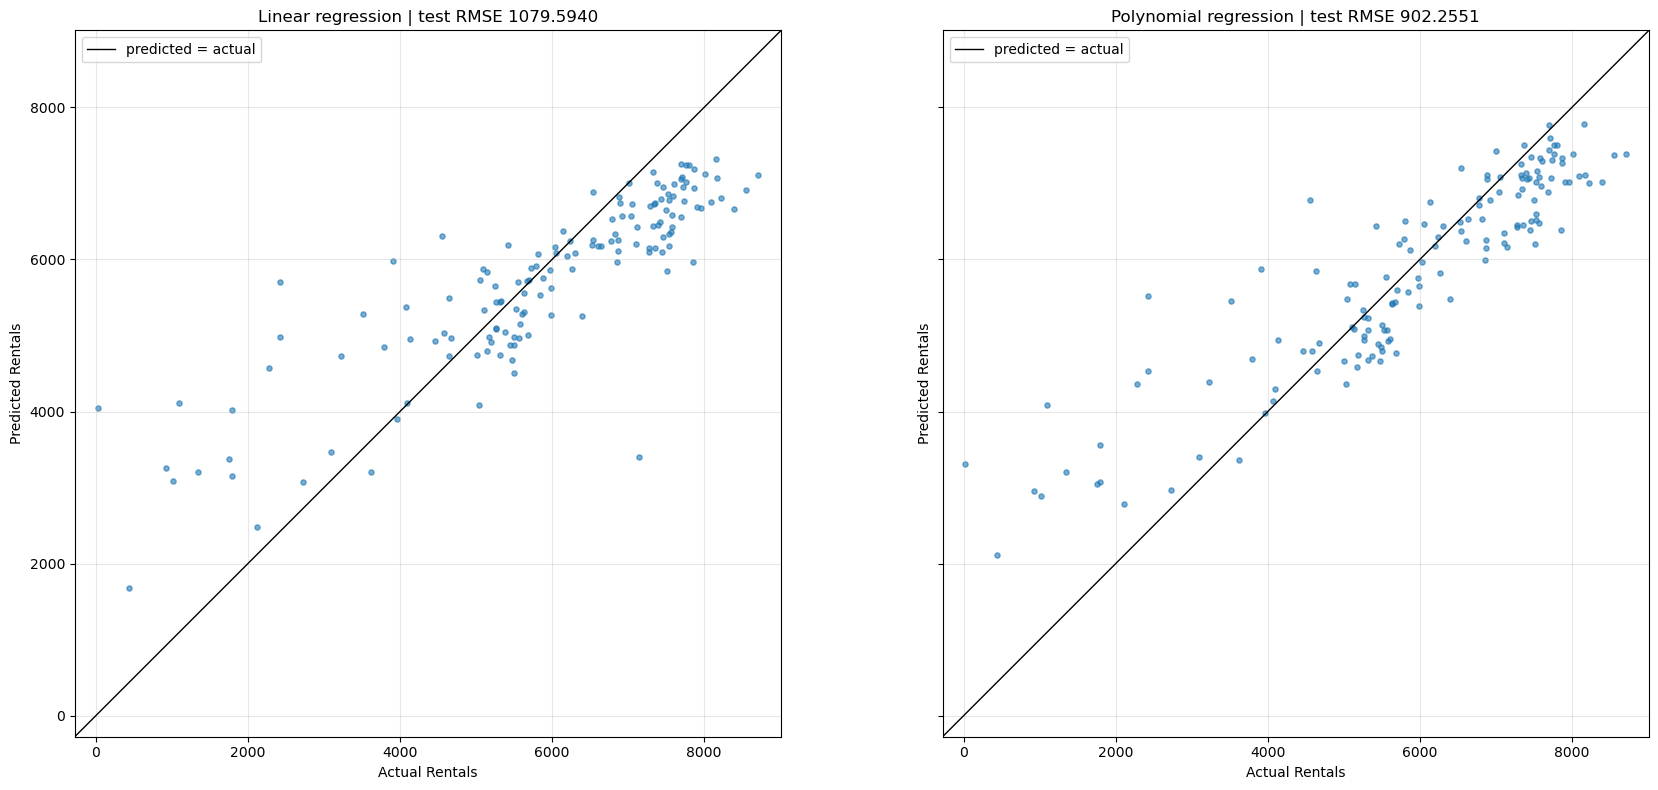

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8), sharex=True, sharey=True)

# one range for both axes of both panels, so the diagonal means the same thing in each
values = predictions[["actual", *MODELS]]
low = values.min().min() - 300
high = values.max().max() + 300

for ax, name in zip(axes, MODELS):
	ax.scatter(predictions["actual"], predictions[name], s=14, alpha=0.6, color="C0")
	ax.plot([low, high], [low, high], color="black", linewidth=1, label="predicted = actual")
	ax.set_xlim(low, high)
	ax.set_ylim(low, high)
	ax.set_aspect("equal")
	ax.set_xlabel(f"Actual {TARGET}")
	ax.set_ylabel(f"Predicted {TARGET}")
	ax.set_title(f"{name} | test RMSE {summary.loc[name, 'test RMSE']:.4f}")
	ax.grid(alpha=0.3)
	ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

## Predictions by Date
The top panel shows the actual Rentals and each model's prediction for every test day. The bottom panel shows predicted minus actual: above 0 the model predicted too high, below 0 too low.

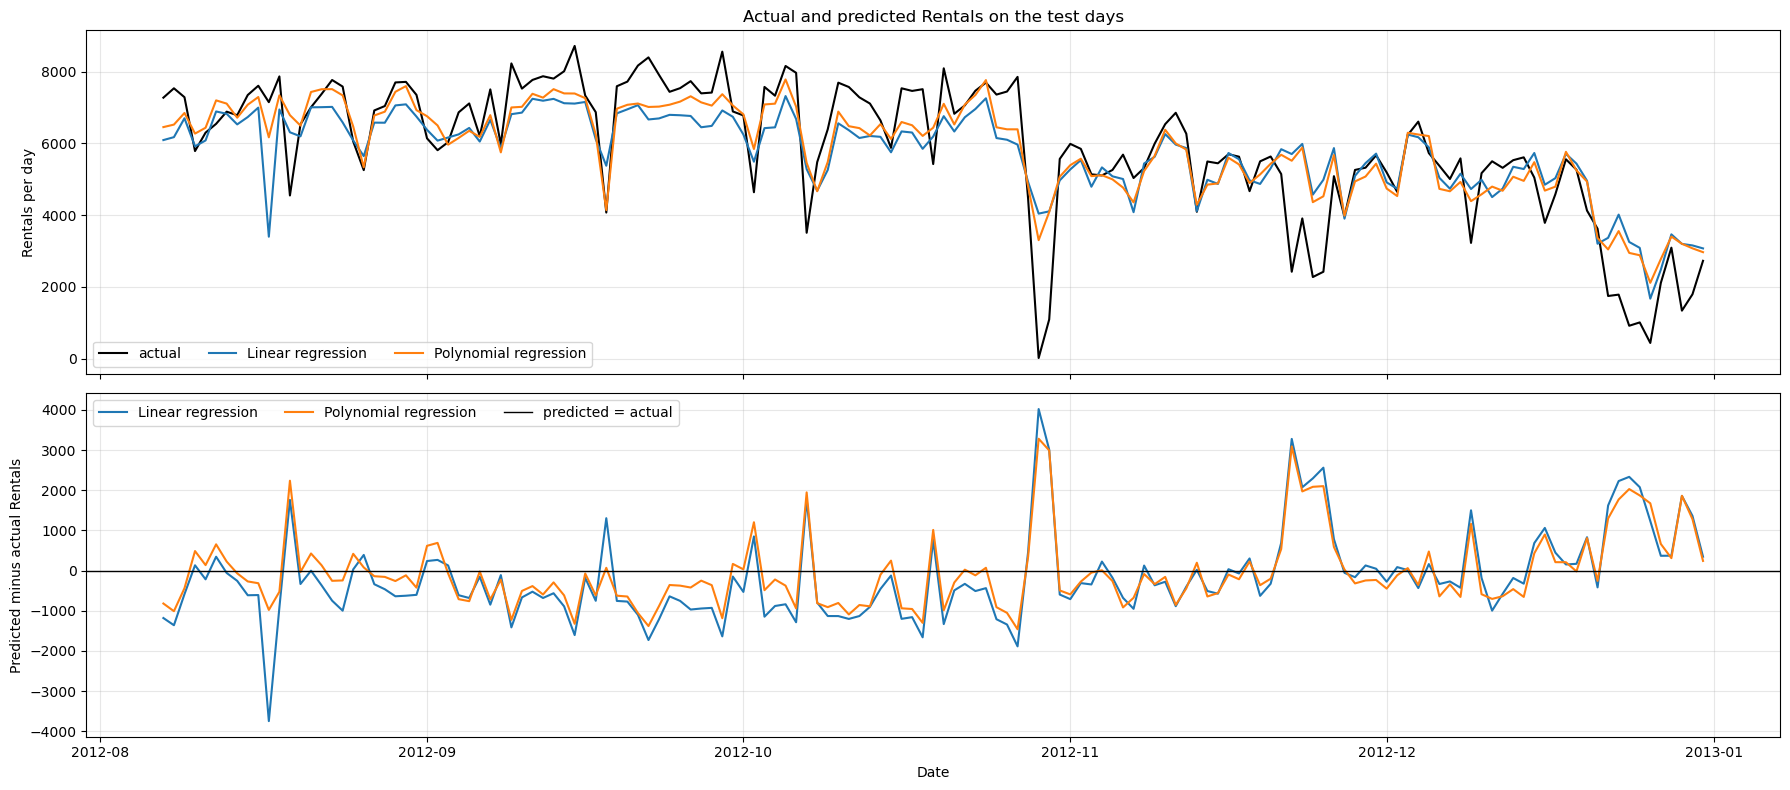

In [9]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(18, 8), sharex=True)

top.plot(predictions["Date"], predictions["actual"], color="black", linewidth=1.5, label="actual")
# the same color for a model in both panels
for i, name in enumerate(MODELS):
	top.plot(predictions["Date"], predictions[name], color=f"C{i}", linewidth=1.5, label=name)
	bottom.plot(predictions["Date"], predictions[name] - predictions["actual"], color=f"C{i}", linewidth=1.5, label=name)
bottom.axhline(0, color="black", linewidth=1, label="predicted = actual")

top.set_title(f"Actual and predicted {TARGET} on the test days")
top.set_ylabel(f"{TARGET} per day")
bottom.set_ylabel(f"Predicted minus actual {TARGET}")
bottom.set_xlabel("Date")
# each legend in one row, in a corner the lines do not reach
top.legend(loc="lower left", ncol=3)
bottom.legend(loc="upper left", ncol=3)
for ax in (top, bottom):
	ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Test RMSE by Month
The folds in Parts D and E each looked 31 days ahead of their training rows. The test set covers 147 days, so the test RMSE of each model is also shown per month. August has only the days from the 7th.

In [10]:
# one row per test month, in date order
monthly = pd.DataFrame({
	month: {
		"days": len(rows),
		**{name: Q2_CROSS_VALIDATION.rmse_of(rows["actual"], rows[name]) for name in MODELS},
	}
	for month, rows in predictions.groupby(predictions["Date"].dt.month_name(), sort=False)
}).T.astype({"days": int})

# the single day each model misses by the most
for name in MODELS:
	worst = predictions.loc[(predictions[name] - predictions["actual"]).abs().idxmax()]
	print(f"{name} | largest miss: {worst['Date']:%Y-%m-%d} | actual {worst['actual']:.1f} | predicted {worst[name]:.1f} | predicted minus actual {worst[name] - worst['actual']:+.1f}")

monthly.round(4)

Linear regression | largest miss: 2012-10-29 | actual 22.0 | predicted 4043.1 | predicted minus actual +4021.1
Polynomial regression | largest miss: 2012-10-29 | actual 22.0 | predicted 3304.2 | predicted minus actual +3282.2


,days,Linear regression,Polynomial regression
August,25,1020.4152,627.6563
September,30,896.9045,685.1130
October,31,1354.9861,1153.4200
November,30,1041.5444,948.3180
December,31,1011.3477,942.1374


**Findings.** Both saved models were loaded and used exactly as Parts D and E left them. The linear model is Lasso (`penalty='l1'`, alpha 0.001, eta0 0.01) with 12 coefficients. The polynomial model is degree 3 with Lasso (`penalty='l1'`, alpha 0.001, eta0 0.001) and 41 coefficients. Each predicted all 147 test days from the 11 raw attributes.

- **Test RMSE.** The linear model scores 1079.5940 and the polynomial model scores 902.2551. A typical miss is about 1080 rentals per day for the linear model and about 900 for the polynomial model.
- **Linear against polynomial.** The polynomial model is ahead by 177.3390. This notebook has one test set and no measure of noise for that difference. What the month table adds is that the lead does not come from one stretch of days: the polynomial model has the lower RMSE in each of the five months. Its lead is widest in August (627.6563 against 1020.4152) and narrows month by month to December (942.1374 against 1011.3477).
- **Training against test.** Both models score much worse on the test days than on the days they were fit on. The gap is 447.4664 for the linear model (632.1276 to 1079.5940) and 322.8633 for the polynomial model (579.3917 to 902.2551). Every test day is later than every training day, and the folds of Parts D and E showed the same direction: a model scored on later days does worse than on the days it was fit on. On the training rows the polynomial model leads by 52.7359. On the test rows it leads by 177.3390. Its extra columns fit the training rows more closely and also predict the later days better, which is the opposite of what overfitting would show.
- **By month.** Neither model's RMSE rises steadily with the distance from the training rows. The linear model is between 896.9045 and 1041.5444 in four of the five months. The polynomial model is lowest in the first two months (627.6563 in August, 685.1130 in September) and higher in the last three (942.1374 to 1153.4200). October is the worst month for both (1354.9861 and 1153.4200), and it sits in the middle of the test period, not at the end. October holds the largest single miss of both models: on 2012-10-29 the actual value is 22, and the models predict 4043.1 and 3304.2.
- **Where the predictions miss, by value.** In both scatter panels the dots follow the diagonal, and both models pull the extremes toward the middle. Days with an actual value below about 3500 are all predicted too high. Days with an actual value above about 7500 are nearly all predicted too low. At that high end the polynomial model's dots sit closer to the diagonal than the linear model's.
- **Where the predictions miss, by date.** From August through October the actual line is above both predictions on most days, most clearly for the linear model, which is about 500 to 1500 too low on many of them. The largest misses in the other direction come in three short stretches, where rentals drop for a few days and both models stay high: the end of October (the 2012-10-29 miss and the day after it, about 3000 too high), late November (about 2000 to 3300 too high for four days in a row) and late December (about 2000 too high for several days). One large miss belongs to the linear model alone: in mid-August it predicts about 3400 on a day with about 7100 rentals, a miss of about 3700, while the polynomial model is about 1000 too low on that day.

**Summary.** On the 147 days neither model has seen, the best linear model misses by about 1080 rentals per day and the best polynomial model by about 900 (test RMSE 1079.5940 and 902.2551). The polynomial model does better on the test days overall and in every month, and its lead over the linear model is larger on the test rows than on the training rows. Both models are much less accurate on the test days than on the training days (test minus train of 447.4664 and 322.8633). Their largest misses are short runs of days with few rentals, which both models predict far too high.

# Reproducibility
This notebook has no random step. The split is by date, with no shuffle. It loads the two models saved by Parts D and E, which were fit with `random_state=42`, and only predicts with them. Running Part D, Part E and then this notebook again gives the same numbers.